# ¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?


In [1]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from mibici_mlops.config import FECHA_INICIO, FIGURES_DIR, INTERIM_DATA_DIR, SEMILLA

import matplotlib.pyplot as plt
import pandas as pd

import folium

## 1. Carga de Datos



In [2]:
viajes = pd.read_parquet(INTERIM_DATA_DIR / 'viajes.parquet')
viajes.info()

# No mostramos usuario_id, genero ni anio_nacimiento: son datos personales y no se usan en P3
DATOS_PERSONALES = ['usuario_id', 'genero', 'anio_nacimiento']
viajes.drop(columns=DATOS_PERSONALES).head()

<class 'pandas.DataFrame'>
RangeIndex: 39078226 entries, 0 to 39078225
Data columns (total 14 columns):
 #   Column           Dtype         
---  ------           -----         
 0   viaje_id         int64         
 1   usuario_id       int64         
 2   genero           str           
 3   anio_nacimiento  float64       
 4   inicio           datetime64[ms]
 5   fin              datetime64[ms]
 6   origen_id        int32         
 7   destino_id       int32         
 8   origen           str           
 9   destino          str           
 10  origen_lon       float64       
 11  origen_lat       float64       
 12  destino_lon      float64       
 13  destino_lat      float64       
dtypes: datetime64[ms](2), float64(5), int32(2), int64(2), str(3)
memory usage: 6.9 GB


,viaje_id,inicio,fin,origen_id,destino_id,origen,destino,origen_lon,origen_lat,destino_lon,destino_lat
0,4601,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47,(GDL-045) C. Pedro Moreno / C. Marsella,(GDL-045) C. Pedro Moreno / C. Marsella,-103.370147,20.675444,-103.370147,20.675444
1,4604,2014-12-01 01:06:54,2014-12-01 01:08:45,5,5,(GDL-004) C. Ghilardi /C. Miraflores,(GDL-004) C. Ghilardi /C. Miraflores,-103.362549,20.691847,-103.362549,20.691847
2,4628,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79,(GDL-077) C. Argentina / C. Pedro Moreno,(GDL-077) C. Argentina / C. Pedro Moreno,-103.361340,20.675631,-103.361340,20.675631
3,4631,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79,(GDL-077) C. Argentina / C. Pedro Moreno,(GDL-077) C. Argentina / C. Pedro Moreno,-103.361340,20.675631,-103.361340,20.675631
4,4632,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79,(GDL-077) C. Argentina / C. Pedro Moreno,(GDL-077) C. Argentina / C. Pedro Moreno,-103.361340,20.675631,-103.361340,20.675631


## 2. Exploración de Datos

Para efectos de este objetivo haremos varios análisis repetitivos para también determinar una fecha de inicio que, una vez integrado será decidida en el objetivo 1, pero que nos ayudará aquí a entrenar mejor el primer modelo base para el clustering.

In [3]:
print(f'Hay {viajes.duplicated().sum()} duplicados')
viajes.drop(columns=DATOS_PERSONALES).describe().T

Hay 0 duplicados


,count,mean,min,25%,50%,75%,max,std
viaje_id,39078226.0,23382679.029651,4601.0,11772322.25,23526414.5,35018704.75,46255558.0,13360334.269269
inicio,39078226,2022-01-17 21:40:38.335000,2014-12-01 00:33:47,2019-07-04 17:46:16.750000,2022-05-16 16:27:03,2024-08-06 08:36:22.250000,2026-09-30 23:59:48,NaN
fin,39078226,2022-01-17 21:55:02.825000,2014-12-01 00:36:54,2019-07-04 17:57:03.500000,2022-05-16 16:37:05.500000,2024-08-06 08:47:37.750000,2026-10-01 00:14:52,NaN
origen_id,39078226.0,133.51162,2.0,50.0,94.0,207.0,519.0,100.148437
destino_id,39078226.0,133.341432,2.0,50.0,86.0,212.0,519.0,102.042223
origen_lon,39076203.0,-103.360682,-103.433215,-103.37084,-103.358548,-103.34853,-103.297112,0.018401
origen_lat,39076203.0,20.678157,20.63613,20.670512,20.675461,20.684014,20.739523,0.015224
destino_lon,39076038.0,-103.358983,-103.433215,-103.368312,-103.35699,-103.34806,-103.297112,0.017646
destino_lat,39076038.0,20.678517,20.63613,20.6708,20.675746,20.684342,20.739523,0.015148


In [4]:
# Usemos solo las columnas/características que nos interesan:
columnas_de_interes = ['inicio', 'origen_id', 'destino_id', 'origen', 'destino', 'origen_lon', 'origen_lat', 'destino_lon', 'destino_lat']

# Creamos el dataset que se usuará para este modelo
viajes_loc = viajes[columnas_de_interes].copy()
viajes_loc['inicio'] = pd.to_datetime(viajes_loc['inicio'])


# Agregamos características adicionales: dia, semana y día de la semana
viajes_loc['dia'] = viajes_loc['inicio'].dt.date
num_viajes_por_dia = (
    viajes_loc.groupby('dia')
    .size()
    .reset_index(name='num_viajes')
)

viajes_loc['semana'] = viajes_loc['inicio'].dt.to_period('W')
num_viajes_por_semana = (
    viajes_loc.groupby('semana')
    .size()
    .reset_index(name='num_viajes')
)

viajes_loc['dia_de_semana'] = viajes_loc['inicio'].dt.dayofweek.map(
    {0: "lun", 1: "mar", 2: "mie", 3: "jue",
     4: "vie", 5: "sab", 6: "dom"}
)
num_viajes_por_dia_de_semana = (
    viajes_loc.groupby('dia_de_semana')
    .size()
    .reset_index(name='num_viajes')
)

viajes_loc.head()

,inicio,origen_id,destino_id,origen,destino,origen_lon,origen_lat,destino_lon,destino_lat,dia,semana,dia_de_semana
0,2014-12-01 00:33:47,47,47,(GDL-045) C. Pedro Moreno / C. Marsella,(GDL-045) C. Pedro Moreno / C. Marsella,-103.370147,20.675444,-103.370147,20.675444,2014-12-01,2014-12-01/2014-12-07,lun
1,2014-12-01 01:06:54,5,5,(GDL-004) C. Ghilardi /C. Miraflores,(GDL-004) C. Ghilardi /C. Miraflores,-103.362549,20.691847,-103.362549,20.691847,2014-12-01,2014-12-01/2014-12-07,lun
2,2014-12-01 09:47:20,79,79,(GDL-077) C. Argentina / C. Pedro Moreno,(GDL-077) C. Argentina / C. Pedro Moreno,-103.361340,20.675631,-103.361340,20.675631,2014-12-01,2014-12-01/2014-12-07,lun
3,2014-12-01 09:48:23,79,79,(GDL-077) C. Argentina / C. Pedro Moreno,(GDL-077) C. Argentina / C. Pedro Moreno,-103.361340,20.675631,-103.361340,20.675631,2014-12-01,2014-12-01/2014-12-07,lun
4,2014-12-01 09:48:46,79,79,(GDL-077) C. Argentina / C. Pedro Moreno,(GDL-077) C. Argentina / C. Pedro Moreno,-103.361340,20.675631,-103.361340,20.675631,2014-12-01,2014-12-01/2014-12-07,lun


Revisemos los datos de manera gráfica:

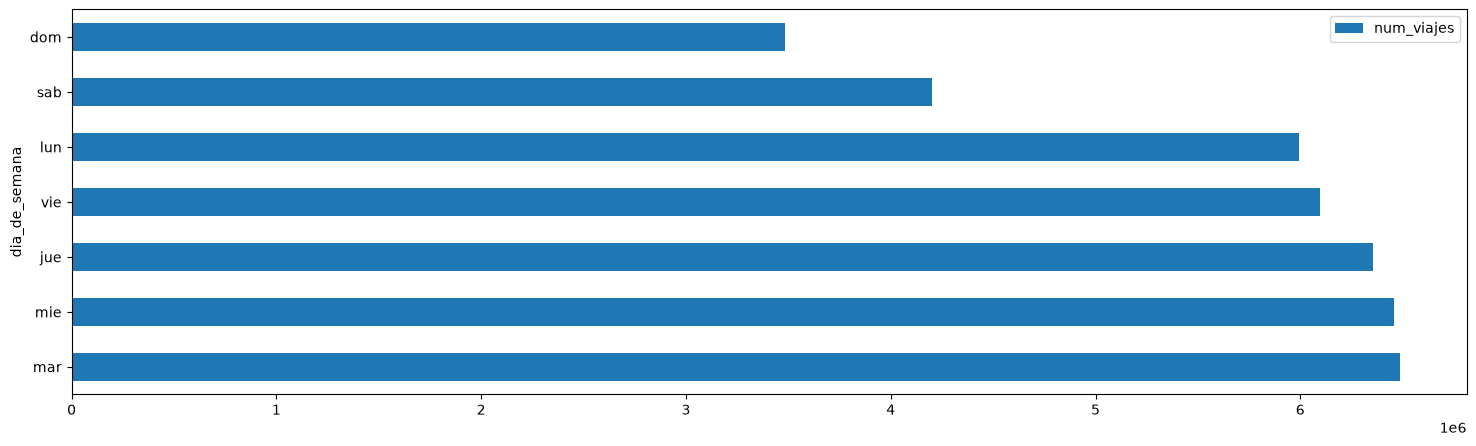

In [5]:
_ = num_viajes_por_dia_de_semana.sort_values(by='num_viajes', ascending=False).plot.barh(x='dia_de_semana', y='num_viajes', figsize=(18, 5))

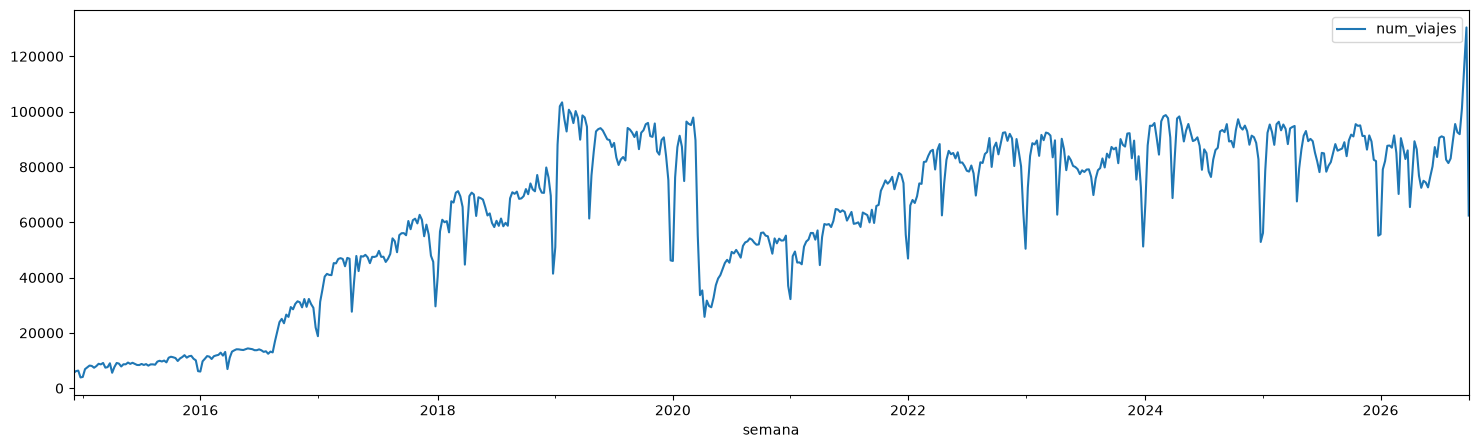

In [6]:
_ = num_viajes_por_semana.plot.line(x='semana', y='num_viajes', figsize=(18, 5))

En el gráfico se puede notar que hay semanas similarmente distanciadas donde hay caídas que, se asume, son semanas festivas como navidad, año nuevo o semana santa.

Confirmemos:

In [7]:
num_viajes_por_semana[num_viajes_por_semana.semana >= '2022-01-01'].sort_values(by='num_viajes', ascending=True).head(20)

,semana,num_viajes
369,2021-12-27/2022-01-02,46876
421,2022-12-26/2023-01-01,50419
473,2023-12-25/2023-12-31,51224
525,2024-12-23/2024-12-29,52876
577,2025-12-22/2025-12-28,55157
578,2025-12-29/2026-01-04,55643
526,2024-12-30/2025-01-05,56128
617,2026-09-28/2026-10-04,62421
384,2022-04-11/2022-04-17,62479
435,2023-04-03/2023-04-09,62745


Confirmado, la única semana que no es navidad, año nuevo o semana santa, es la de 2026-09-28/2026-10-04, pero coincide con el final de los datos provistos:

In [8]:
viajes.inicio.max()

Timestamp('2026-09-30 23:59:48')

Confirmado, la última semana no tiene datos completos.

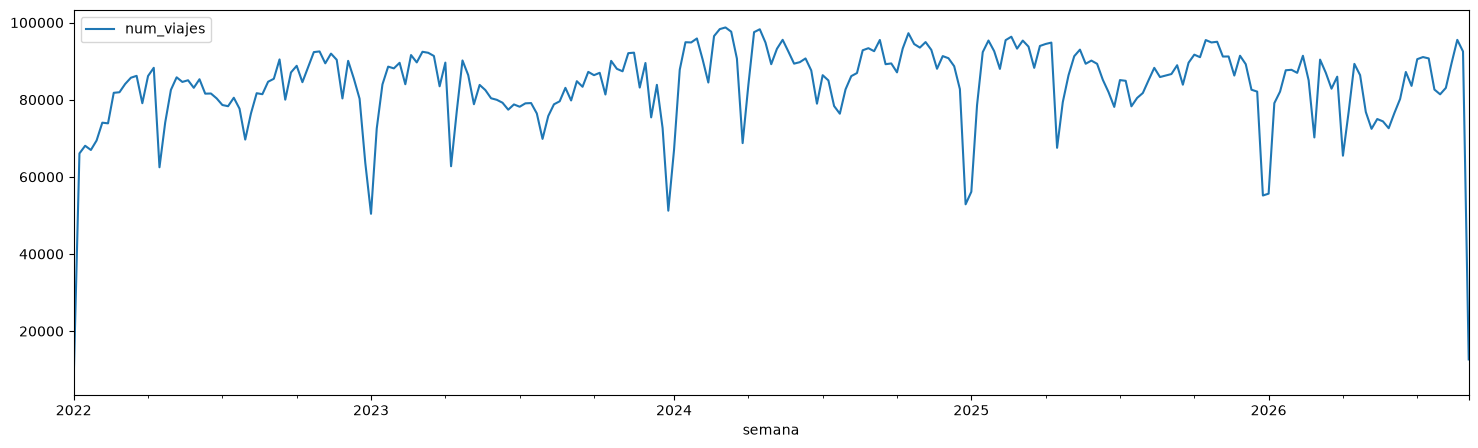

In [9]:
rep = viajes_loc.loc[
    (viajes_loc['inicio'] >= '2022-01-01') &
    (viajes_loc['inicio'] < '2026-09-01')
].copy()

viajes_por_semana = (
    rep.groupby('semana')
    .size()
    .reset_index(name='num_viajes')
    .sort_values('semana')
)

_ = viajes_por_semana.plot.line(x='semana', y='num_viajes', figsize=(18, 5))

Pasemos ahora a incluir estaciones, solo como exploración informativa:

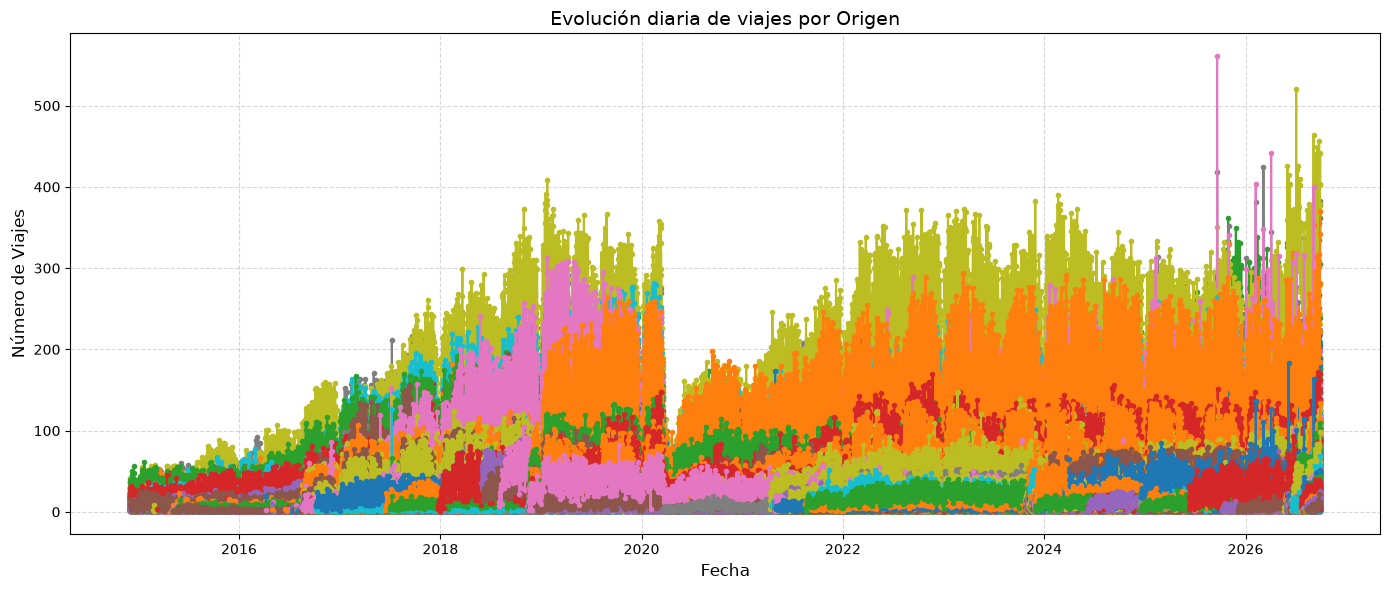

In [10]:
# Agrupamos por día
viajes_por_dia_origen = viajes_loc.groupby(['dia', 'origen_id']).size().reset_index(name='num_viajes')

# Creamos la tabla pivote
tabla_pivot = viajes_por_dia_origen.pivot(
    index='dia', 
    columns='origen_id', 
    values='num_viajes'
)

# La graficamos
plt.figure(figsize=(14, 6))
tabla_pivot.plot(ax=plt.gca(), marker='.', linewidth=1.5, legend=False)

plt.title('Evolución diaria de viajes por Origen', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Número de Viajes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

En el gráfico se aprecia que hay ciertas estaciones que se usan más fecuentemente, también algunas que parecen haber sido cerradas o movidas antes de 2022.

Enfoquémonos ahora en las más importantes:

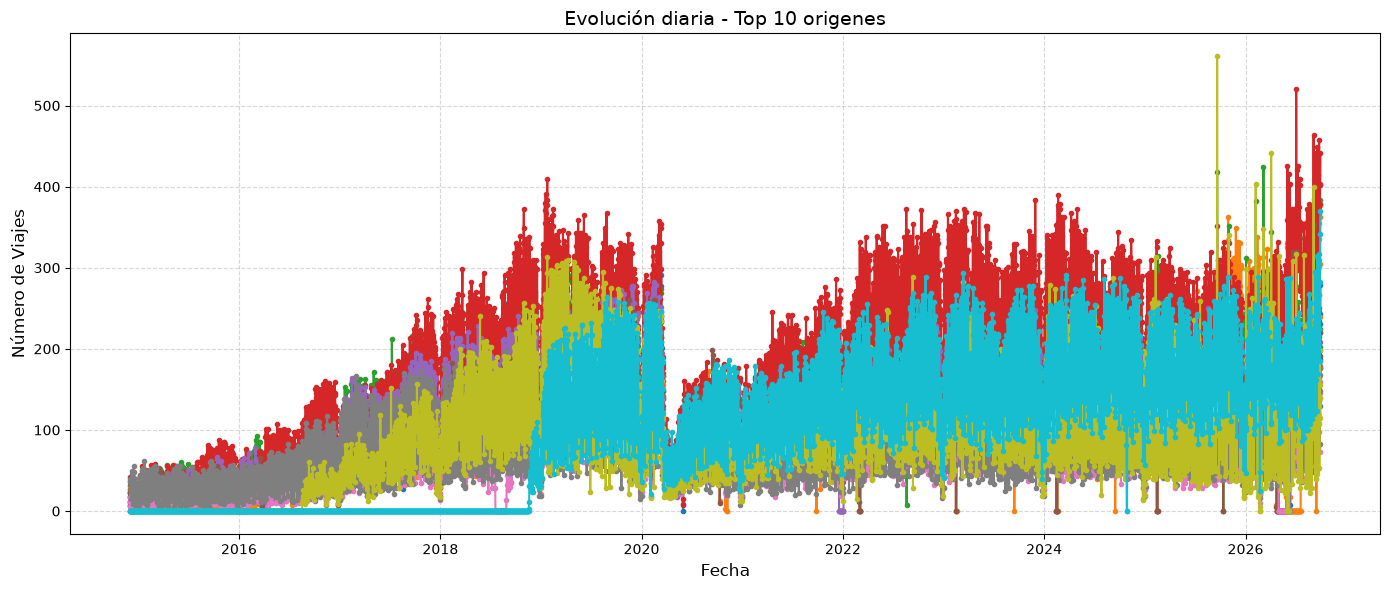

In [11]:
# Top N
n = 10
top_origenes = viajes_loc['origen_id'].value_counts().head(n).index
viajes_top = viajes_loc[viajes_loc['origen_id'].isin(top_origenes)].set_index('origen_id')

# Volvemos a calcular la tabla pivote
tabla_pivot_top = (
    viajes_top.groupby(['dia', 'origen_id'])
    .size()
    .unstack(fill_value=0)
)

# Graficamos
plt.figure(figsize=(14, 6))
tabla_pivot_top.plot(ax=plt.gca(), marker='.', linewidth=1.5, legend=False)

plt.title(f'Evolución diaria - Top {n} origenes', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Número de Viajes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

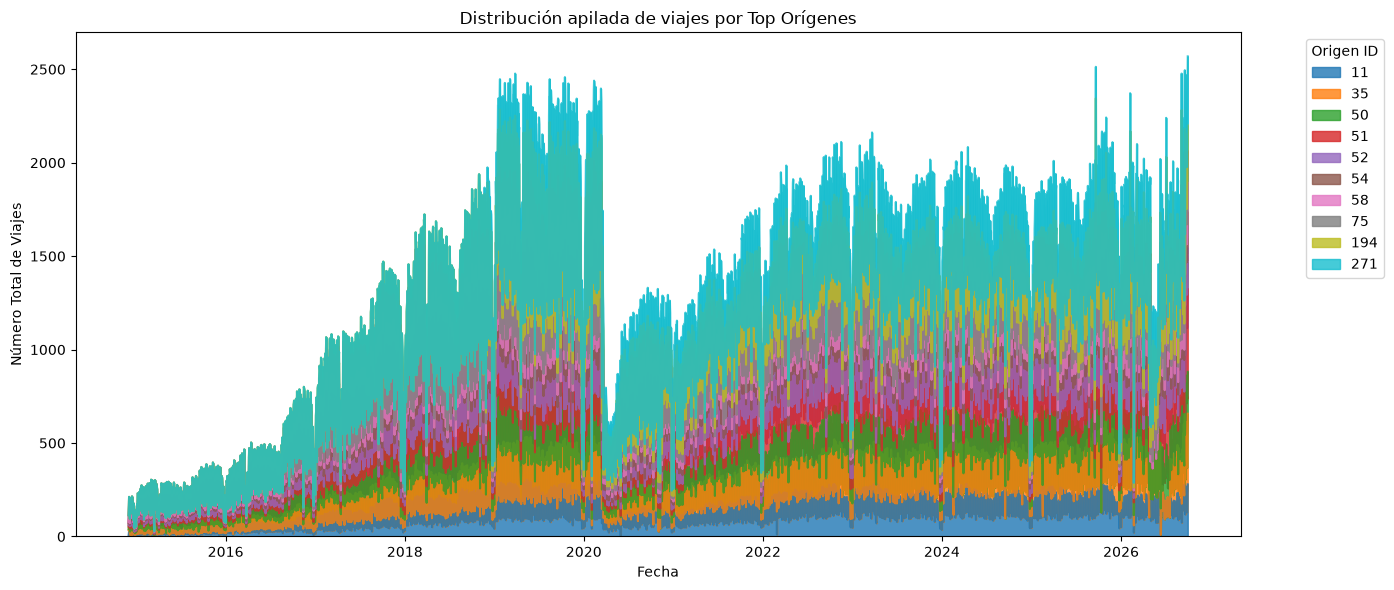

In [12]:
# Mostremos la versión apilada
tabla_pivot_top.plot(kind='area', stacked=True, figsize=(14, 6), alpha=0.8)
plt.title('Distribución apilada de viajes por Top Orígenes')
plt.xlabel('Fecha')
plt.ylabel('Número Total de Viajes')
plt.legend(title='Origen ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [13]:
top_estaciones = (
    viajes_loc.groupby("origen_id")
    .agg(
        origen=("origen", "first"),
        num_viajes=("origen_id", "size")
    )
    .nlargest(n, "num_viajes")
)

top_estaciones.sort_values('num_viajes', ascending=False)

,origen,num_viajes
origen_id,,
51,(GDL-049) Lopez Cotilla / Penitenciaría,840156
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,601475
50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,589305
52,(GDL-050) C.Pedro Moreno /Federalismo,565178
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,562985
54,(GDL-052) Av. Juarez /16 de Septiembre,508270
271,(GDL-198) Av. Alcalde / C. Hospital,476314
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,418005
75,(GDL-073) Av. La Paz / Av. Federalismo,410587


## 3. Modelo Base para Clustering

Ya estudiado y pre-filtrado el conjunto de datos, procedemos a encontrar patrones mediante el uso de un modelo de clustering.

Como modelo base usaremos K-Means, buscando el número K que mejor particione los datos con él. Más adelante se podrán probar más modelos.

In [14]:
# Usamos el periodo acordado para el proyecto (config.FECHA_INICIO, decisión 2)
df = viajes_loc[viajes_loc['inicio'] >= FECHA_INICIO].copy()

# Cada viaje cuenta como una salida desde su estación de origen
eventos = df.dropna(
    subset=['origen_id', 'inicio', 'origen_lon', 'origen_lat']
).copy()

# Día de la semana y franja horaria
dias = {0: 'lun', 1: 'mar', 2: 'mie', 3: 'jue',
        4: 'vie', 5: 'sab', 6: 'dom'}
eventos['dia'] = eventos['inicio'].dt.dayofweek.map(dias)
eventos['franja'] = pd.cut(
    eventos['inicio'].dt.hour,
    bins=[-1, 5, 11, 17, 23],
    labels=['madrugada', 'manana', 'tarde', 'noche']
)
eventos['patron'] = eventos['dia'] + '_' + eventos['franja'].astype(str)

# Una fila por estación y una columna por combinación de día y franja
X = pd.crosstab(eventos['origen_id'], eventos['patron'])

# Comparemos la distribución horaria de cada estación, no su volumen total
X = X.div(X.sum(axis=1), axis=0).fillna(0)

{2: 0.2836190422411491, 3: 0.30834999061384716, 4: 0.24237753127218978, 5: 0.19002681393094614, 6: 0.1891689723016544, 7: 0.17041443124693653}


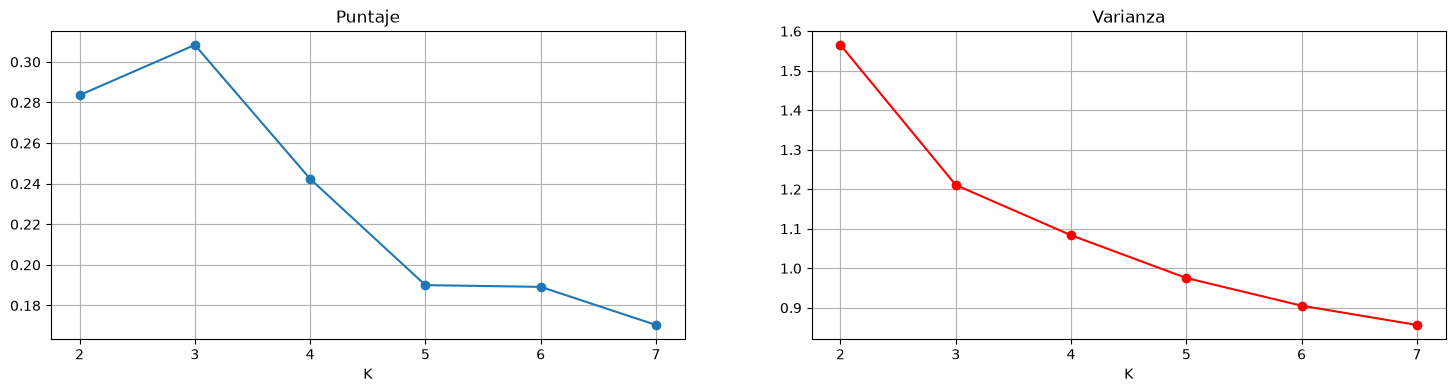

In [15]:
# Calculemos los puntajes con distintos valores para K
puntajes = {}
varianzas = {}

for k in range(2, min(8, len(X))):
    modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    etiquetas = modelo.fit_predict(X)
    puntajes[k] = silhouette_score(X, etiquetas)
    varianzas[k] = modelo.inertia_

print(puntajes)

#Graficando
_,axes = plt.subplots(1,2, figsize=(18,4))

axes[0].plot(puntajes.keys(), puntajes.values(), marker='o')
axes[0].set_title('Puntaje')
axes[0].set_xlabel('K')
axes[0].grid(True)

axes[1].plot(varianzas.keys(), varianzas.values(), color='red', marker='o')
axes[1].set_title('Varianza')
axes[1].set_xlabel('K')
axes[1].grid(True)
plt.show()

De lo anterior se nota que el mejor puntaje es cuando **K=3**, también nos lo confirma la gráfica de varianza que, como es esperado, la varianza en cada cluster tiende a 0 ya que cuanto más grupos menos puntos por grupo, pero se alcanza a notar que hay un salto más inclinado entre 2 y 3, y menor de 3 en adelante.

Seleccionado **K** pasemos al modelo base:

In [16]:
# Establecemos K
k = 3

# Creamos el modelo
modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)

# Lo entrenamos
estaciones = X.copy()
estaciones["cluster"] = modelo.fit_predict(X)

# Perfil promedio: muestra en qué días y franjas se concentra cada grupo
print(estaciones.groupby("cluster")[X.columns].mean().round(2).T)

cluster           0     1     2
patron                         
dom_madrugada  0.00  0.00  0.00
dom_manana     0.04  0.03  0.12
dom_noche      0.02  0.02  0.02
dom_tarde      0.04  0.04  0.09
jue_madrugada  0.00  0.00  0.00
jue_manana     0.07  0.04  0.04
jue_noche      0.04  0.05  0.04
jue_tarde      0.05  0.06  0.04
lun_madrugada  0.00  0.00  0.00
lun_manana     0.06  0.04  0.04
lun_noche      0.04  0.05  0.04
lun_tarde      0.05  0.06  0.04
mar_madrugada  0.00  0.00  0.00
mar_manana     0.07  0.04  0.05
mar_noche      0.04  0.06  0.05
mar_tarde      0.05  0.07  0.05
mie_madrugada  0.00  0.00  0.00
mie_manana     0.07  0.04  0.04
mie_noche      0.04  0.06  0.05
mie_tarde      0.05  0.07  0.05
sab_madrugada  0.00  0.00  0.00
sab_manana     0.04  0.03  0.03
sab_noche      0.03  0.03  0.03
sab_tarde      0.05  0.05  0.05
vie_madrugada  0.00  0.00  0.00
vie_manana     0.06  0.04  0.04
vie_noche      0.04  0.05  0.04
vie_tarde      0.05  0.06  0.04


### Visualizar los clusters

Ahora que ya está el modelo entrenado, podemos visualizar el resultado en un mapa de Guadalajara.

In [17]:
# Agrupamos por estación
coords = viajes.groupby("origen_id")[["origen_lon", "origen_lat", "destino_lon", "destino_lat"]].median()
estaciones = estaciones.join(coords, how="left")
estaciones.info()

<class 'pandas.DataFrame'>
Index: 471 entries, 2 to 519
Data columns (total 33 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   dom_madrugada  471 non-null    float64
 1   dom_manana     471 non-null    float64
 2   dom_noche      471 non-null    float64
 3   dom_tarde      471 non-null    float64
 4   jue_madrugada  471 non-null    float64
 5   jue_manana     471 non-null    float64
 6   jue_noche      471 non-null    float64
 7   jue_tarde      471 non-null    float64
 8   lun_madrugada  471 non-null    float64
 9   lun_manana     471 non-null    float64
 10  lun_noche      471 non-null    float64
 11  lun_tarde      471 non-null    float64
 12  mar_madrugada  471 non-null    float64
 13  mar_manana     471 non-null    float64
 14  mar_noche      471 non-null    float64
 15  mar_tarde      471 non-null    float64
 16  mie_madrugada  471 non-null    float64
 17  mie_manana     471 non-null    float64
 18  mie_noche      471 non-nul

In [18]:
# Creamos el mapa
mapa = folium.Map(
    location=[viajes.origen_lat.mean(), viajes.origen_lon.mean()],
    zoom_start=14,
    tiles="OpenStreetMap"
)

# Ponemos cada punto en el mapa con color para cada grupo
grupos = sorted(estaciones["cluster"].dropna().unique())
paleta = ["red", "blue", "green"]
colores = {grupo: paleta[i % len(paleta)] for i, grupo in enumerate(grupos)}

for grupo in grupos:
    capa = folium.FeatureGroup(name=f"Grupo {grupo}")

    puntos = estaciones[estaciones["cluster"] == grupo]

    for estacion_id, fila in puntos.iterrows():
        folium.CircleMarker(
            location=[fila["origen_lat"], fila["origen_lon"]],
            radius=5,
            color=colores[grupo],
            fill=True,
            fill_color=colores[grupo],
            fill_opacity=0.8,
            tooltip=f"Estación {estacion_id} · Grupo {grupo}"
        ).add_to(capa)

    capa.add_to(mapa)

# Desplegamos y guardamos el mapa
folium.LayerControl().add_to(mapa)
mapa.save(f"{FIGURES_DIR}/fig1-origenes.html")
mapa

Volvemos a hacer lo mismo para visualizar los destinos de esos mismos viajes.

In [19]:
mapa = folium.Map(
    location=[viajes.origen_lat.mean(), viajes.origen_lon.mean()],
    zoom_start=14,
    tiles="OpenStreetMap"
)

grupos = sorted(estaciones["cluster"].dropna().unique())
paleta = ["red", "blue", "green", "purple", "orange"]
colores = {grupo: paleta[i % len(paleta)] for i, grupo in enumerate(grupos)}

for grupo in grupos:
    capa = folium.FeatureGroup(name=f"Grupo {grupo}")

    puntos = estaciones[estaciones["cluster"] == grupo]

    for estacion_id, fila in puntos.iterrows():
        folium.CircleMarker(
            location=[fila["destino_lat"], fila["destino_lon"]],
            radius=5,
            color=colores[grupo],
            fill=True,
            fill_color=colores[grupo],
            fill_opacity=0.8,
            tooltip=f"Estación {estacion_id} · Grupo {grupo}"
        ).add_to(capa)

    capa.add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa.save(f"{FIGURES_DIR}/fig2-destinos.html")
mapa

Veamos las caracteristicas más importante de cada grupo/cluster:

In [20]:
print(estaciones.cluster.value_counts())
perfil = estaciones.groupby("cluster")[X.columns].mean()

colores_esp = ['Rojo', 'Azul', 'Verde']
for grupo, valores in perfil.iterrows():
    print(f"Grupo {grupo} ({colores_esp[grupo]}): {valores.nlargest(3).to_dict()}")

cluster
0    220
1    212
2     39
Name: count, dtype: int64
Grupo 0 (Rojo): {'mar_manana': 0.06879530160872352, 'mie_manana': 0.06796154955183643, 'jue_manana': 0.06553390644011178}
Grupo 1 (Azul): {'mar_tarde': 0.06745842868785622, 'mie_tarde': 0.06627206284183754, 'vie_tarde': 0.06391851170683316}
Grupo 2 (Verde): {'dom_manana': 0.11879954598683792, 'dom_tarde': 0.08845140854036931, 'mar_tarde': 0.04716456108667956}


## 4. Conclusiones Preliminares

- Hay tres grupos principales de estaciones con patrones similares (con los viajes desde `FECHA_INICIO`, 2022-03-01):
1. Un grupo menor de 39 estaciones (verde) que tiene un mayor uso los domingos por la mañana y por la tarde, y que se muestra en una línea casi horizontal que cubre la ciudad de este a oeste.
2. Un grupo de 212 estaciones (azul) que se usa más entre semana por las tardes. Está ubicado principalmente al poniente (130 de 212), hacia Zapopan, pero incluye parte del centro de Guadalajara.
3. Un grupo de 220 estaciones (rojo), de tamaño similar al anterior, con mayor uso entre semana por las mañanas y que se compone principalmente de estaciones del centro y oriente de Guadalajara (175 de 220), incluido el norte.

- El grupo pequeño adquiere importancia en domingos, con una demanda muy posiblemente relacionada al uso en la Vía RecreActiva.

- El mayor uso en las mañanas se da en Guadalajara y en las tardes en Zapopan.

- Los destinos de los viajes no se cruzan entre grupos, solo se concentran más.

- Las estaciones cercanas al transporte público, especialmente cerca del tren ligero, tienen actividad alta por las mañanas.